# 02 - No-show prediction (CRISP-DM phases 4 and 5)

This notebook takes over `Prediction_No_Show.ipynb` of the conference paper: same split, same SMOTE, same four models and hyperparameter grids, same metrics computed the same way (`utils_ml.py`). The changes are announced in a **Correction** box where they act:

1. `discontinued` and `service_time` are not predictors any more (notebook 01, section 3.6).
2. SMOTE and the scaler are inside the cross-validation (a pipeline), so that the synthetic no-shows of a fold are never used to score that fold.
3. The decision threshold is chosen on a validation set (part of the training set), never on the test set.
4. The MLP stops on its own validation data, not on the test set.
5. The probabilities are calibrated on the validation set (Platt scaling) before the optimisation (notebook 04).
6. The categorical variables with many values (zip, sta3n, state, stopcode) are target-encoded instead of integer codes, whose order means nothing (zip 437 is not "between" 436 and 438).
7. StandardScaler instead of MinMaxScaler: with MinMaxScaler and batches of 256 the MLP only predicted "show" (pilot run on 10 % of the consultations); the tree models are not affected by the scaling.
8. Feature importances: the same method for the four models, permutation importance with a bootstrap on the test set (the paper retrained each tree model on bootstrap samples of the train set).

## Outline
- [0 - Parameters](#0)
- [1 - Data and split](#1)
- [2 - Models](#2): [Random Forest](#2.1), [XGBoost](#2.2), [AdaBoost](#2.3), [MLP](#2.4)
- [3 - Comparison of the models](#3)
- [4 - Probabilities for the scheduling model](#4)

In [1]:
import sys
sys.path.insert(0, "..")          # utils_ml.py is at the root of the repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
import xgboost as xgb
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from utils_ml import *

<a name="0"></a>
## 0 - Parameters

Every choice of this notebook is set in the cell below, with its reason.

In [2]:
DATA_PATH = "../data/data_prep.parquet"      # written by 01_data_preparation.ipynb
SPLIT_PATH = "../data/split.parquet"         # train / validation / test of each consultation, reused by notebook 03
SCORES_PATH = "../data/test_scores.parquet"  # no-show probabilities of the test consultations, read by notebook 04
TARGET = "NoShow"
NOT_PREDICTORS = ["service_time"]             # target of notebook 03, known only after the consultation

# Share of the consultations used: 0.1 for a pilot run, 1.0 for the final run.
SAMPLE_FRACTION = 1.0
RANDOM_STATE = 0                              # as in the paper

# Trained models are saved here (not versioned: large) and loaded instead of trained when the
# notebook is run again, for a quick restart and to reproduce the results with the same models.
MODELS_DIR = "../models/no_show"
RETRAIN = False                               # True: train again even if a saved model exists

# Categorical variables with many values (zip 910, sta3n 130, state 66, stopcode 36). Each value is
# replaced by the no-show rate observed for it in the train set (target encoding, smoothed towards
# the overall rate for rare values). On the train set it is computed by 5-fold cross-fitting, so a
# consultation never sees its own outcome; validation and test use the rates of the whole train set.
CATEGORICAL = ["sta3n", "stopcode", "zip", "state"]
TARGET_ENCODER = dict(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE)

TEST_SIZE = 0.3                               # as in the paper: 70 % train, 30 % test, stratified
VALIDATION_SIZE = 0.15                        # Correction: share of the train set kept aside to choose the threshold
SMOTE_RATIO = 0.33                            # as in the paper: after SMOTE, no-shows = 33 % of the shows (train only)
CV_FOLDS = 3                                  # as in the paper
SCORING = "f1_macro"                          # the models are optimised for the F1 score, averaged as in the paper's metrics
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)   # candidate decision thresholds

# Hyperparameter grids of the paper (Prediction_No_Show.ipynb).
GRID_RF = {"n_estimators": [100], "max_depth": [10, 15, 20], "min_samples_split": [2, 5],
           "min_samples_leaf": [2, 4], "max_features": ["sqrt"], "class_weight": ["balanced"]}
GRID_XGB = {"n_estimators": [1000], "max_depth": [20, 25], "min_child_weight": [2], "gamma": [0.3],
            "subsample": [0.4], "reg_alpha": [0.2], "learning_rate": [0.01, 0.1]}
XGB_SCALE_POS_WEIGHT = 1 / SMOTE_RATIO        # as in the paper: shows / no-shows after SMOTE
GRID_ADA = {"n_estimators": [100], "learning_rate": [0.05, 0.1]}
# MLP of the paper: 16-8-4 ReLU, Adam, early stopping with patience 10, at most 50 epochs.
# scikit-learn instead of Keras (one dependency less); no dropout layer in scikit-learn, an L2
# penalty (alpha) plays that role; batch of 256 instead of 32 (10 M rows: 8 times fewer steps).
MLP_PARAMS = dict(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam", alpha=1e-4,
                  batch_size=256, max_iter=50, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=10, random_state=RANDOM_STATE)

# Feature importances (all four models): drop of the F1 score when a feature is shuffled, on N_BOOTSTRAP
# samples of PERMUTATION_ROWS test rows drawn with replacement; the trained model is not retrained.
PERMUTATION_ROWS = 200_000
N_BOOTSTRAP = 10                              # default number of iterations of the paper's bootstrap function
RELIABILITY_BINS = 20                         # bins of the reliability diagrams


<a name="1"></a>
## 1 - Data and split

In [3]:
data = pd.read_parquet(DATA_PATH)
if SAMPLE_FRACTION < 1:
    data = data.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE)
# The categorical variables first: the encoder of the pipeline outputs them first.
FEATURES = CATEGORICAL + [c for c in data.columns if c not in CATEGORICAL + [TARGET] + NOT_PREDICTORS]
print(f"{len(data):,} consultations, no-show rate {data[TARGET].mean():.4f}")
print(f"{len(FEATURES)} predictors: {FEATURES}")
data[CATEGORICAL].nunique().to_frame("distinct values")

11,342,613 consultations, no-show rate 0.0311
14 predictors: ['sta3n', 'stopcode', 'zip', 'state', 'dta', 'dts', 'non_va', 'typecare', 'day_of_week', 'day_of_month', 'month', 'hour', 'prior_noShow_rate', 'prior_service_time_avg']


,distinct values
sta3n,130
stopcode,36
zip,907
state,64


As in the paper: 70 % train, 30 % test, stratified on the target.

> **Correction.** The paper chose the decision threshold by looking at the test set (0.6 for the Random Forest, 0.49 for AdaBoost). Here 15 % of the train set is kept aside as a **validation** set: the threshold is chosen there, and the test set is only used once, to report the metrics.

In [4]:
rows_train, rows_test = train_test_split(data.index, test_size=TEST_SIZE, random_state=RANDOM_STATE,
                                         stratify=data[TARGET], shuffle=True)
rows_train, rows_val = train_test_split(rows_train, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE,
                                        stratify=data.loc[rows_train, TARGET])
split = pd.concat([pd.Series("train", index=rows_train), pd.Series("validation", index=rows_val),
                   pd.Series("test", index=rows_test)]).rename("part").rename_axis("row").sort_index()
split.to_frame().to_parquet(SPLIT_PATH)

X_train, y_train = data.loc[rows_train, FEATURES], data.loc[rows_train, TARGET].to_numpy()
X_val, y_val = data.loc[rows_val, FEATURES], data.loc[rows_val, TARGET].to_numpy()
X_test, y_test = data.loc[rows_test, FEATURES], data.loc[rows_test, TARGET].to_numpy()
summary = pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
                        "no-shows": [y_train.sum(), y_val.sum(), y_test.sum()]},
                       index=["train", "validation", "test"])
summary["no-show rate"] = summary["no-shows"] / summary["rows"]
summary

,rows,no-shows,no-show rate
train,6748854,209660,0.031066
validation,1190975,36999,0.031066
test,3402784,105711,0.031066


<a name="2"></a>
## 2 - Models

> **Correction.** In the paper SMOTE was applied to the whole train set before the cross-validation: the synthetic no-shows built from a consultation could then be scored in another fold, which flatters the cross-validation scores. Here the target encoder, then SMOTE, then the StandardScaler, then the model form one pipeline (`make_pipeline`): in each fold they only see the training part of the fold. The best pipeline is refit the same way on the whole train set; validation and test are never resampled.

For each model: grid search (`train_model`), then the threshold chosen on the validation set, the five metrics on train and test, the ROC curve, the errors and the feature importances (`evaluate_classifier`).

In [5]:
models, probas, thresholds, results = {}, {}, {}, {}

def run(name, model, grid):
    pipeline = make_pipeline(model, CATEGORICAL, TARGET_ENCODER, SMOTE_RATIO, RANDOM_STATE)
    models[name], cv, minutes, loaded = train_model(pipeline, grid, X_train, y_train, SCORING, CV_FOLDS, RANDOM_STATE,
                                                    f"{MODELS_DIR}/{name}.joblib", RETRAIN)
    print(f"{name}: loaded from {MODELS_DIR} (trained in {minutes:.1f} min)" if loaded else f"{name}: trained in {minutes:.1f} min")
    if cv is not None:
        print("Best hyperparameters:", cv.iloc[0]["params"])
        display(cv)
    probas[name] = {part: models[name].predict_proba(X)[:, 1]
                    for part, X in [("train", X_train), ("val", X_val), ("test", X_test)]}

def evaluate(name):
    thresholds[name], results[name] = evaluate_classifier(
        name, models[name], probas[name], y_train, y_val, y_test, X_test, THRESHOLDS,
        FEATURES, PERMUTATION_ROWS, N_BOOTSTRAP, RANDOM_STATE)
    display(results[name].round(4))

<a name="2.1"></a>
### 2.1 - Random Forest

Random Forest: trained in 87.5 min
Best hyperparameters: {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
9,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.631246,0.003460,112.233862
10,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.630846,0.003391,109.984512
11,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.630846,0.003391,104.868162
8,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.630737,0.002907,113.394193
4,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.603757,0.001893,179.320431
5,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.603069,0.002700,191.938206
7,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.603036,0.002020,184.594191
6,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.603036,0.002020,187.793256
0,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.575209,0.000705,113.959981
1,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.574633,0.001761,112.851912


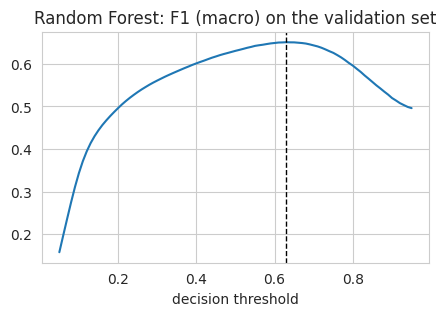

Threshold chosen on the validation set: 0.63


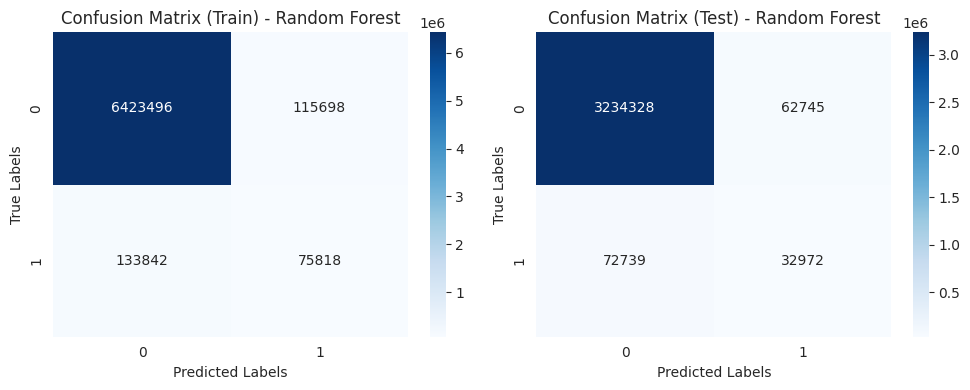

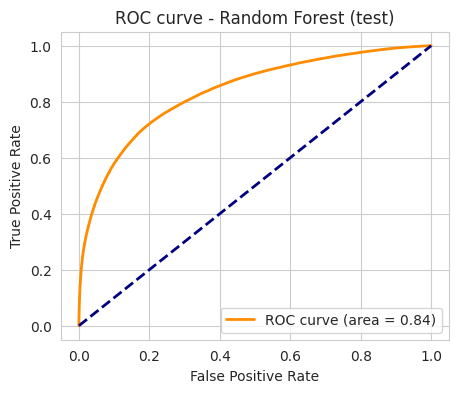

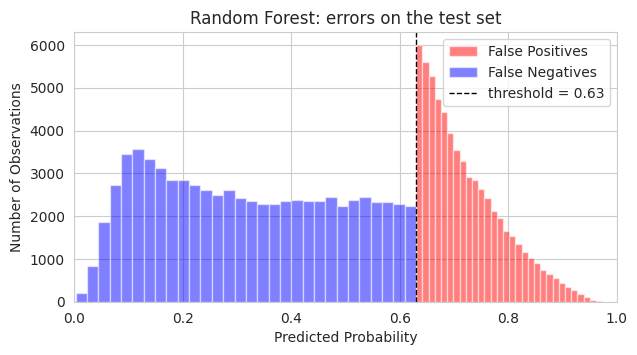

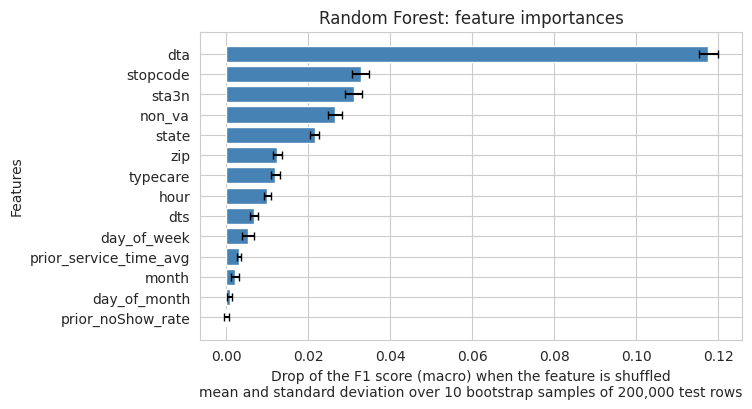

,Train,Test
Metric,,
Recall,0.6720,0.6464
AUC,0.8723,0.8359
Accuracy,0.9630,0.9602
Precision,0.6877,0.6612
F1 Score,0.6795,0.6534


In [6]:
run("Random Forest", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE), GRID_RF)
evaluate("Random Forest")

<a name="2.2"></a>
### 2.2 - XGBoost

XGBoost: trained in 778.0 min
Best hyperparameters: {'gamma': 0.3, 'learning_rate': 0.01, 'max_depth': 20, 'min_child_weight': 2, 'n_estimators': 1000, 'reg_alpha': 0.2, 'subsample': 0.4}


,params,mean_test_score,std_test_score,mean_fit_time
0,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.680114,0.005334,3074.751976
1,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.678451,0.002959,5294.073072
3,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.670759,0.002833,2534.352802
2,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.669702,0.002509,2623.750731


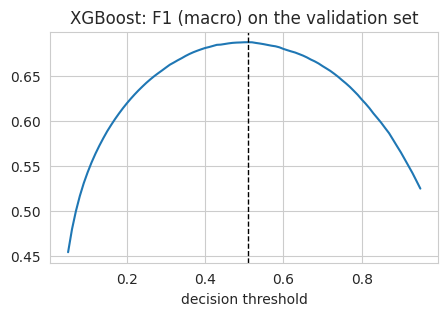

Threshold chosen on the validation set: 0.51


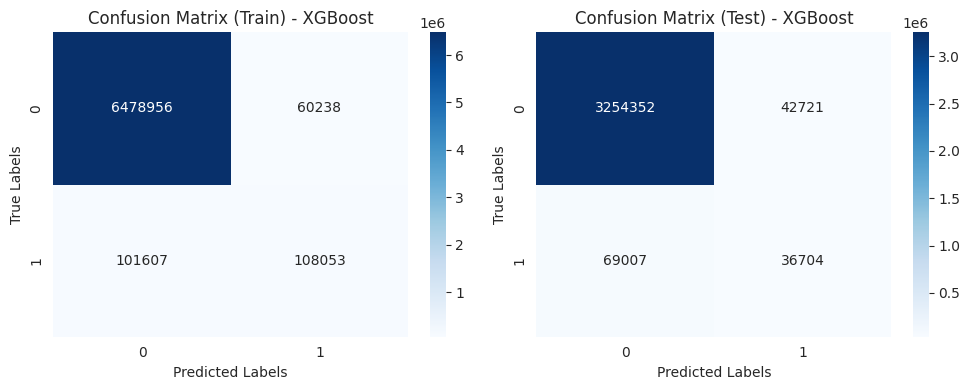

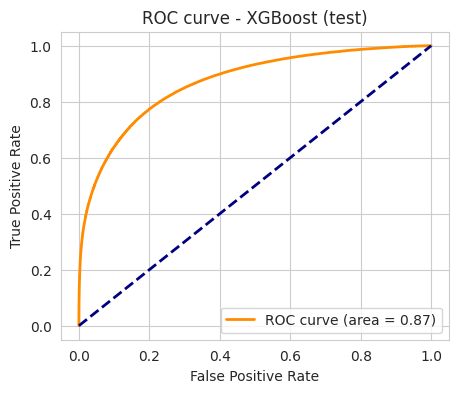

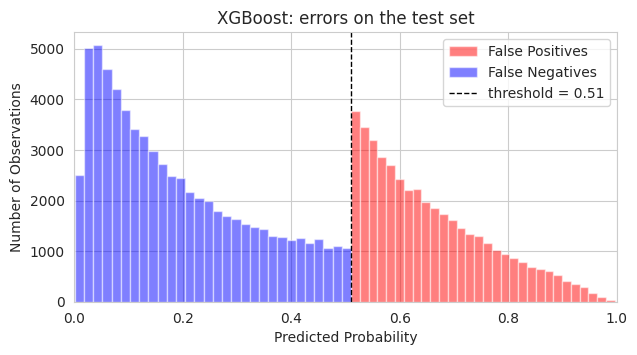

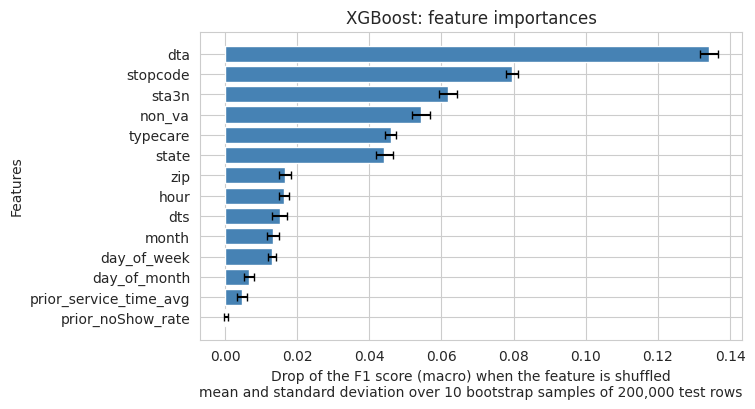

,Train,Test
Metric,,
Recall,0.7531,0.6671
AUC,0.9577,0.8694
Accuracy,0.9760,0.9672
Precision,0.8133,0.7207
F1 Score,0.7797,0.6898


In [7]:
run("XGBoost", xgb.XGBClassifier(objective="binary:logistic", scale_pos_weight=XGB_SCALE_POS_WEIGHT,
                                 tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), GRID_XGB)
evaluate("XGBoost")

<a name="2.3"></a>
### 2.3 - AdaBoost

AdaBoost: trained in 97.7 min
Best hyperparameters: {'learning_rate': 0.1, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
1,"{'learning_rate': 0.1, 'n_estimators': 100}",0.596891,0.001336,772.452916
0,"{'learning_rate': 0.05, 'n_estimators': 100}",0.578684,0.000641,789.400816


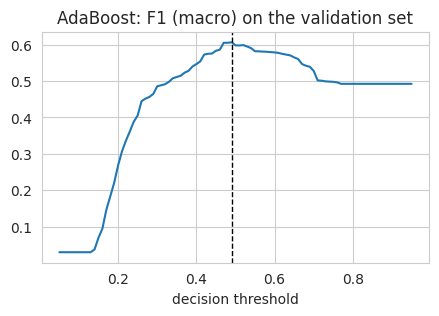

Threshold chosen on the validation set: 0.49


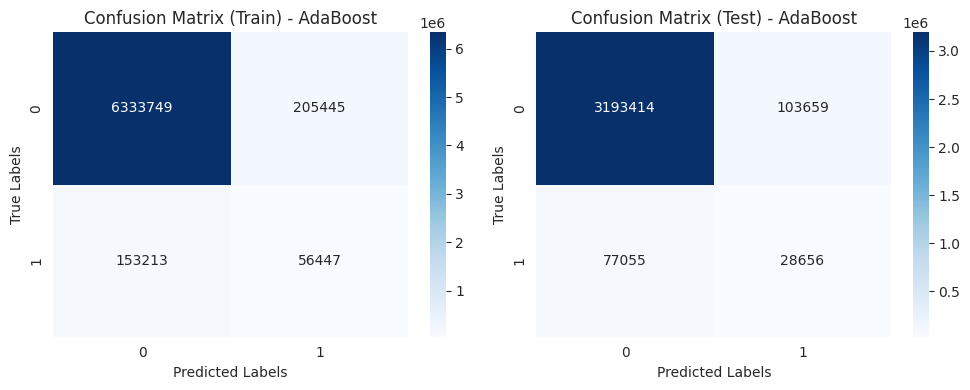

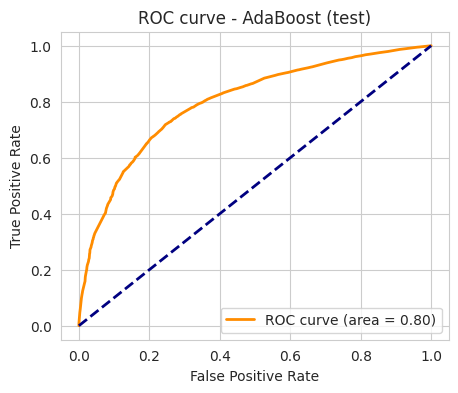

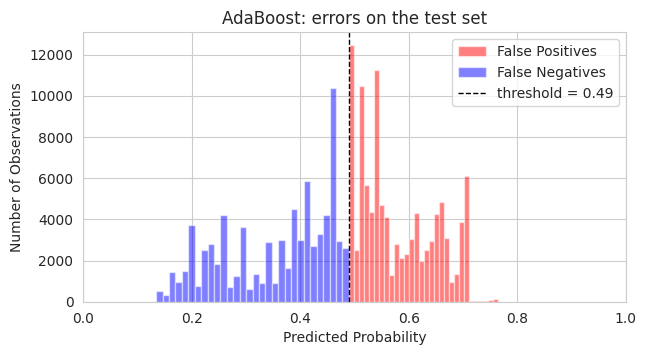

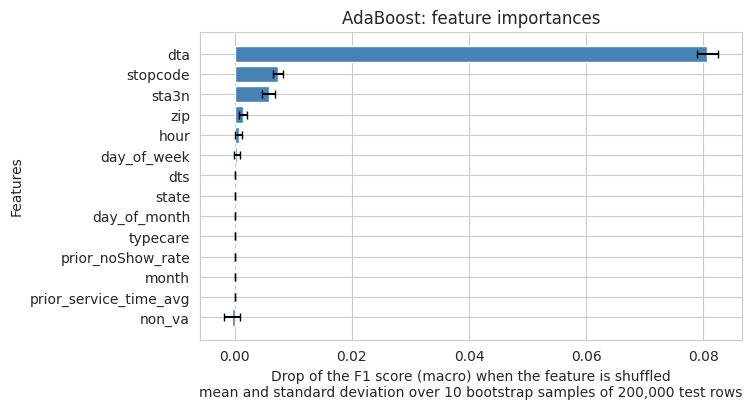

,Train,Test
Metric,,
Recall,0.6189,0.6198
AUC,0.7985,0.7985
Accuracy,0.9469,0.9469
Precision,0.5960,0.5965
F1 Score,0.6059,0.6066


In [8]:
run("AdaBoost", AdaBoostClassifier(random_state=RANDOM_STATE), GRID_ADA)
evaluate("AdaBoost")

<a name="2.4"></a>
### 2.4 - MLP

> **Correction.** In the paper the MLP stopped when its loss on the **test** set stopped improving (`validation_data=(X_test, y_test)`), so the test set took part in the training. Here it stops on 10 % of its own training data (`early_stopping=True`).

MLP: trained in 7.1 min


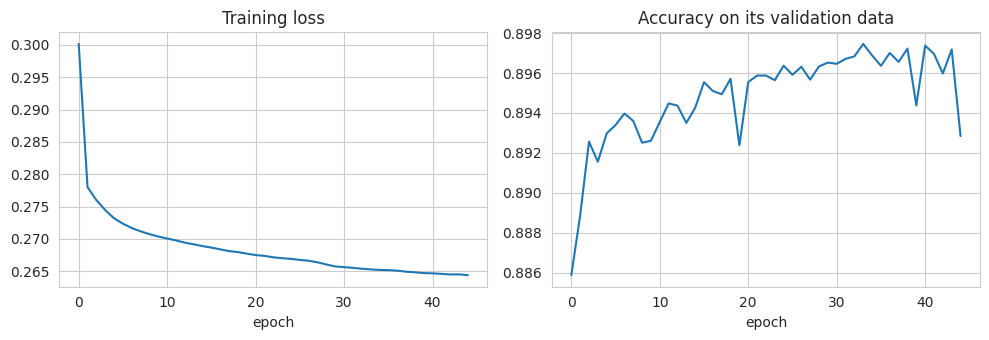

Stopped after 45 epochs


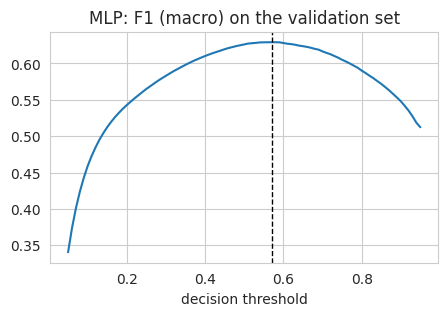

Threshold chosen on the validation set: 0.57


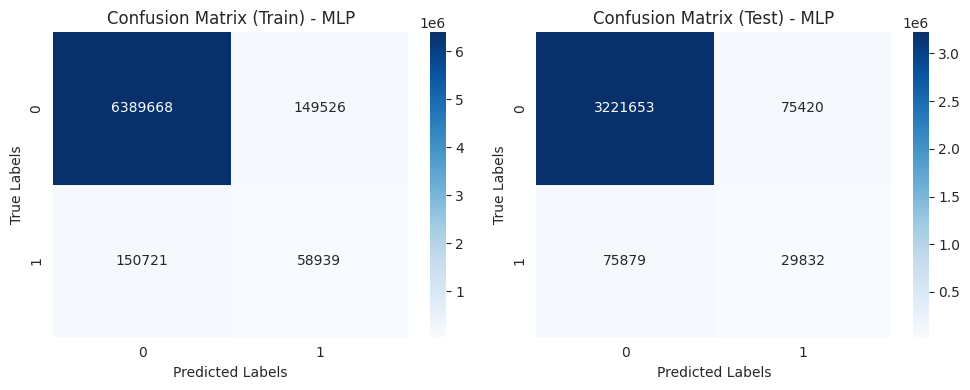

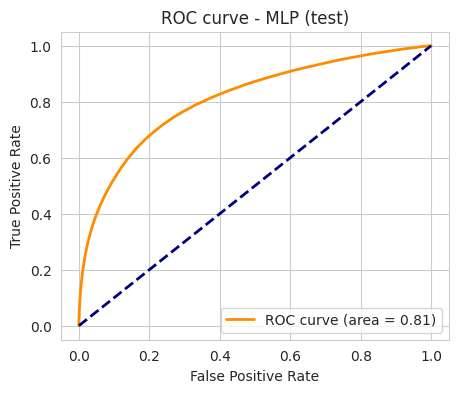

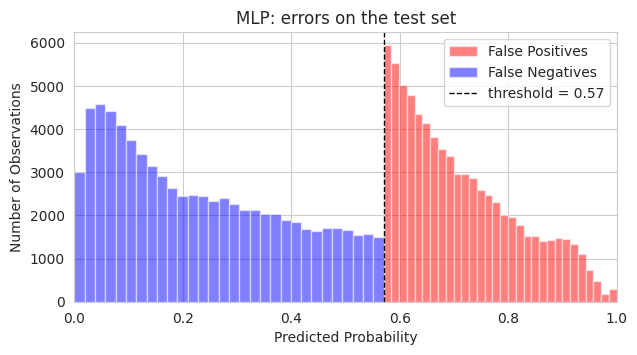

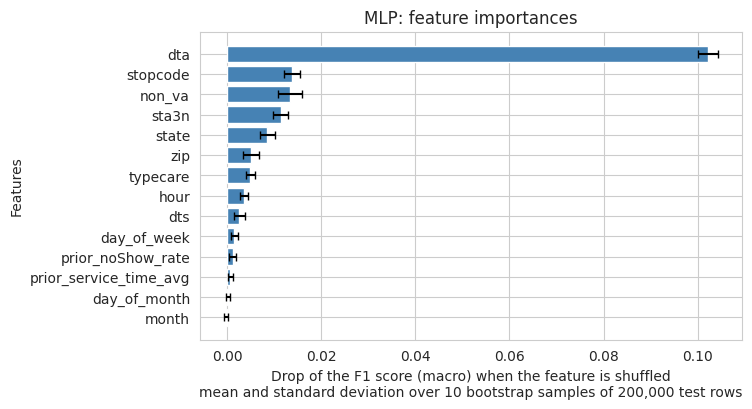

,Train,Test
Metric,,
Recall,0.6291,0.6297
AUC,0.8089,0.8089
Accuracy,0.9555,0.9555
Precision,0.6298,0.6302
F1 Score,0.6295,0.6299


In [9]:
run("MLP", MLPClassifier(**MLP_PARAMS), None)
mlp = models["MLP"].named_steps["model"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(mlp.loss_curve_); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(mlp.validation_scores_); ax[1].set_title("Accuracy on its validation data"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print(f"Stopped after {mlp.n_iter_} epochs")
evaluate("MLP")

<a name="3"></a>
## 3 - Comparison of the models

The five metrics of the four models on the train set and on the test set, with the threshold of each model.

In [10]:
summary = pd.concat({"Train": pd.DataFrame({name: res["Train"] for name, res in results.items()}),
                     "Test": pd.DataFrame({name: res["Test"] for name, res in results.items()})})
summary.loc[("", "Threshold"), :] = pd.Series(thresholds)
summary.round(4)

Random Forest  XGBoost  AdaBoost     MLP
      Metric                                             
Train Recall            0.6720   0.7531    0.6189  0.6291
      AUC               0.8723   0.9577    0.7985  0.8089
      Accuracy          0.9630   0.9760    0.9469  0.9555
      Precision         0.6877   0.8133    0.5960  0.6298
      F1 Score          0.6795   0.7797    0.6059  0.6295
Test  Recall            0.6464   0.6671    0.6198  0.6297
      AUC               0.8359   0.8694    0.7985  0.8089
      Accuracy          0.9602   0.9672    0.9469  0.9555
      Precision         0.6612   0.7207    0.5965  0.6302
      F1 Score          0.6534   0.6898    0.6066  0.6299
      Threshold         0.6300   0.5100    0.4900  0.5700

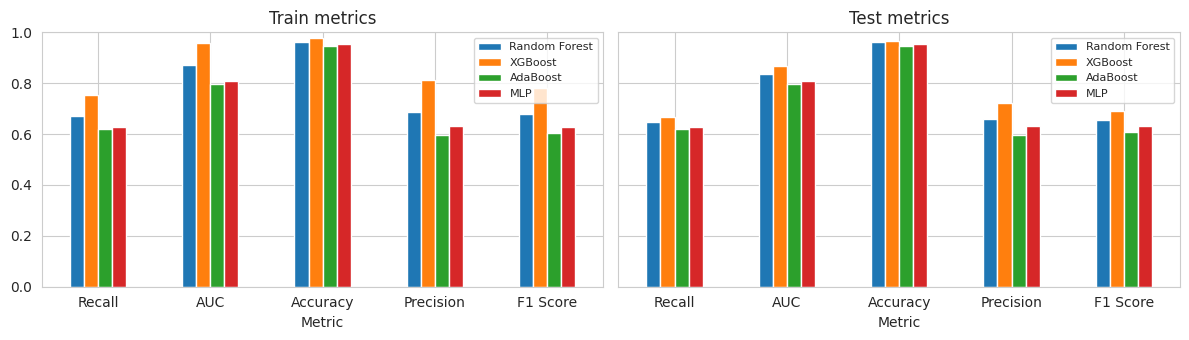

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for axis, part in zip(ax, ["Train", "Test"]):
    summary.loc[part].plot.bar(ax=axis, rot=0)
    axis.set_ylim(0, 1); axis.set_title(f"{part} metrics"); axis.legend(fontsize=8)
plt.tight_layout(); plt.show()

The model used for the scheduling is the one with the best F1 score on the **validation** set (the test set does not take part in the choice).

In [12]:
val_f1 = pd.Series({name: f1_score(y_val, (probas[name]["val"] >= thresholds[name]).astype(int), average="macro")
                    for name in models})
print("F1 (macro) on the validation set:"); print(val_f1.round(4).to_string())
BEST = val_f1.idxmax()
print(f"\nModel used for the scheduling: {BEST}")

F1 (macro) on the validation set:
Random Forest    0.6509
XGBoost          0.6881
AdaBoost         0.6063
MLP              0.6292

Model used for the scheduling: XGBoost


<a name="4"></a>
## 4 - Probabilities for the scheduling model

The scheduling model (notebook 04) needs the **probability** that each patient comes, not only a yes/no prediction. The models were trained on data where no-shows are much more frequent than in reality (SMOTE, class weights), so their scores are not probabilities at the real rate. Platt scaling (`platt_scaling`; Platt, 1999) fits a logistic regression with two parameters on the **validation** set, from the score of the model to the observed no-show. It is monotone, so the ranking of the consultations and the AUC are unchanged. The reliability diagram below compares the scores before and after on the validation set: well-calibrated probabilities lie on the diagonal; the test set then gets the calibrated probabilities.

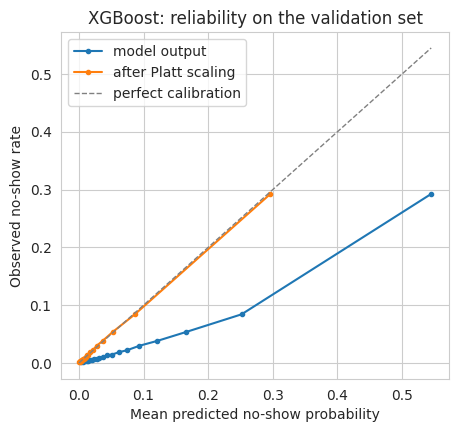

Mean no-show probability on validation: model 0.0806, calibrated 0.0310, observed rate 0.0311
Mean no-show probability on test: calibrated 0.0311, observed rate 0.0311


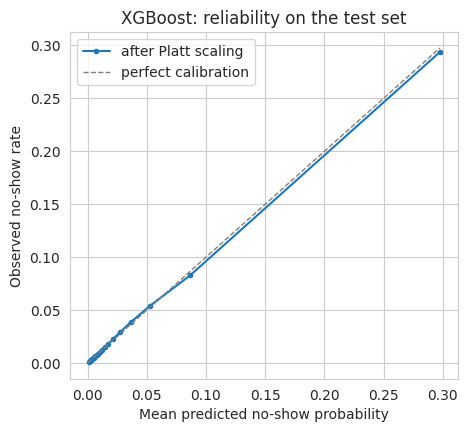

In [13]:
calibrate = platt_scaling(probas[BEST]["val"], y_val)
val_calibrated = calibrate(probas[BEST]["val"])
plot_reliability(y_val, {"model output": probas[BEST]["val"], "after Platt scaling": val_calibrated},
                 RELIABILITY_BINS, f"{BEST}: reliability on the validation set")
print(f"Mean no-show probability on validation: model {probas[BEST]['val'].mean():.4f}, "
      f"calibrated {val_calibrated.mean():.4f}, observed rate {y_val.mean():.4f}")
test_calibrated = calibrate(probas[BEST]["test"])
print(f"Mean no-show probability on test: calibrated {test_calibrated.mean():.4f}, observed rate {y_test.mean():.4f}")
plot_reliability(y_test, {"after Platt scaling": test_calibrated}, RELIABILITY_BINS, f"{BEST}: reliability on the test set")

Export, for every consultation of the test set (identified by its row in `data_prep.parquet`): its calibrated no-show probability and whether it was actually a no-show.

In [14]:
test_scores = pd.DataFrame({
    "row": rows_test,
    "p_noshow": test_calibrated,
    "NoShow": y_test,
})
test_scores.to_parquet(SCORES_PATH, index=False)
print(f"Saved {SCORES_PATH}: {len(test_scores):,} test consultations, model {BEST}")
test_scores.drop(columns="row").describe()

Saved ../data/test_scores.parquet: 3,402,784 test consultations, model XGBoost


,p_noshow,NoShow
count,3.402784e+06,3.402784e+06
mean,3.108656e-02,3.106603e-02
std,7.823906e-02,1.734962e-01
min,7.302188e-05,0.000000e+00
25%,4.240800e-03,0.000000e+00
50%,9.462232e-03,0.000000e+00
75%,2.424179e-02,0.000000e+00
max,9.946148e-01,1.000000e+00
